## 03 - QC Expression Matrix

### Aim
* Run quality control on the raw TPM matrix before handing it to a TME deconvolution tool, and flag samples that warrant manual review - without dropping any samples/genes automatically (deconvolution tools intersect against their own signature gene lists, so pre-filtering here would only risk losing genes a signature needs).

### Input
* `data/processed/TCGA-PAAD_TPM_raw.tsv` and `TCGA-PAAD_sample_metadata.tsv` from notebook 02.
* `clinical.project-tcga-paad.2026-10-20/clinical.tsv` (sibling of `data/` under this pipeline's root, `progress/`) for the sex cross-check.

### Output
* `data/qc/qc_report.txt` - text summary of all checks.
* `data/qc/flagged_samples.tsv` - union of samples flagged by any check, for manual review.
* `data/qc/pca_sample_type.png`, `data/qc/sample_correlation_heatmap.png` - diagnostic plots.
* `data/qc/sex_check.tsv` - per-sample XIST/RPS4Y1 expression vs. clinical reported sex, with a `sex_mismatch` (TRUE/FALSE) indicator column.
* `data/qc/batch_effect_check.txt` - variance-explained (R^2) by tumor/normal status vs. TCGA collection site (TSS) and plate, on the top 5 PCs - the evidence base for the quantile-normalization decision below.

### Steps
1. TPM sanity: column sums should be ~1e6 (definition of TPM).
2. Sample type counts (tumor vs normal) match GDC expectations.
3. Duplicate / near-duplicate samples (same patient, or Spearman r > 0.99 pair on log2(TPM+1)).
4. Gene detection rate per sample (fraction of genes with TPM > 0).
5. PCA on log2(TPM+1), top-variance genes - flag PC1/PC2 outliers (> 3 SD).
6. Sample-sample correlation heatmap.
7. Sex-check: XIST vs RPS4Y1 expression against clinical `sex_at_birth`.
8. Batch-effect check: quantify how much PC1-PC5 variance is explained by TCGA collection site (TSS) / plate (technical) vs. tumor/normal status (biological) - this is the basis for not applying quantile normalization (see Conclusion).

### Result
* TPM column sums: median 999,785 (expected ~1,000,000) - 0 samples off by > 1e4.
* Sample types: 178 Primary Tumor, 4 Solid Tissue Normal.
* 4 patients have both a tumor and a normal aliquot (expected pairing, not an error).
* 0 near-duplicate sample pairs (Spearman r > 0.99).
* Mean gene detection rate 54.5%; 1 sample flagged as a detection-rate outlier.
* 8 samples flagged as PCA outliers (> 3 SD on PC1/PC2).
* 4 samples show a clinical-vs-expression sex mismatch.
* 9 unique samples flagged in total across all checks.
* Batch check: TCGA collection site (TSS, 27 sites, single sequencing center) explains more PC1/PC2 variance (R^2 = 0.23 / 0.18) than tumor-vs-normal status does (R^2 = 0.002 / 0.03); plate shows a similar pattern (R^2 = 0.10 / 0.16). A site/plate-associated technical signal is present on the top PCs.

### Conclusion
* The matrix passes the core TPM sanity checks and is internally consistent (TPM sums to ~1e6, no near-duplicate samples). 9 samples are flagged for manual review (low gene detection, PCA outliers, or ambiguous sex signal) before running deconvolution; no samples or genes are removed by this notebook.

RSEM

GEO ID




### Set working directory to the project root

In [1]:
# Jupyter's R kernel starts with the notebook's own folder as the working
# directory. This pipeline's root is progress/ (scripts/ and data/ live
# nested under progress/, not the repo root) - every path below is
# relative to that.
if (basename(getwd()) == "rnaseq_download") setwd(file.path("..", ".."))
getwd()

[1] "/Users/liruixi/Desktop/i20_transfer/QCB/rotation/Alex/XDec_Pancreatic_Cancer/progress"

### Load packages and the processed TPM matrix + sample metadata

In [2]:
library(dplyr)
library(readr)
library(tibble)
library(ggplot2)
library(pheatmap)

proc_dir <- "data/processed"
qc_dir   <- "data/qc"
dir.create(qc_dir, showWarnings = FALSE, recursive = TRUE)

tpm <- read_tsv(file.path(proc_dir, "TCGA-PAAD_TPM_raw.tsv"), show_col_types = FALSE) %>%
  column_to_rownames("gene_symbol") %>% as.matrix()
meta <- read_tsv(file.path(proc_dir, "TCGA-PAAD_sample_metadata.tsv"), show_col_types = FALSE)

report <- character()
add <- function(...) report <<- c(report, sprintf(...))


Attaching package: ‘dplyr’




The following objects are masked from ‘package:stats’:

    filter, lag




The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




### 1. TPM sanity: column sums should be ~1e6

In [3]:
col_sums <- colSums(tpm, na.rm = TRUE)
bad_sum <- names(col_sums)[abs(col_sums - 1e6) > 1e4]
add("TPM column sums: median = %.0f (expect ~1,000,000).", median(col_sums))
add("Samples with column sum off by >1e4 from 1e6: %d", length(bad_sum))

### 2. Sample type counts (tumor vs normal)

In [4]:
type_tab <- table(meta$sample_type)
add("Sample type counts: %s",
    paste(names(type_tab), type_tab, sep = "=", collapse = ", "))

### 3. Duplicate / near-duplicate samples

In [5]:
dup_patients <- meta %>% count(patient) %>% filter(n > 1)
add("Patients with >1 sample/aliquot in the matrix: %d", nrow(dup_patients))

logtpm <- log2(tpm + 1)
sample_cor <- cor(logtpm, method = "spearman")
diag(sample_cor) <- NA
near_dup <- which(sample_cor > 0.99, arr.ind = TRUE)
near_dup_pairs <- unique(t(apply(near_dup, 1, sort)))
add("Sample pairs with Spearman r > 0.99 on log2(TPM+1): %d", nrow(near_dup_pairs))

### 4. Gene detection rate per sample

In [6]:
detect_rate <- colMeans(tpm > 0)
low_detect <- names(detect_rate)[detect_rate < (mean(detect_rate) - 3 * sd(detect_rate))]
add("Mean gene detection rate (TPM>0): %.1f%% | samples flagged as outliers (<mean-3sd): %d",
    100 * mean(detect_rate), length(low_detect))

### 5. PCA on log2(TPM+1), top-variance genes

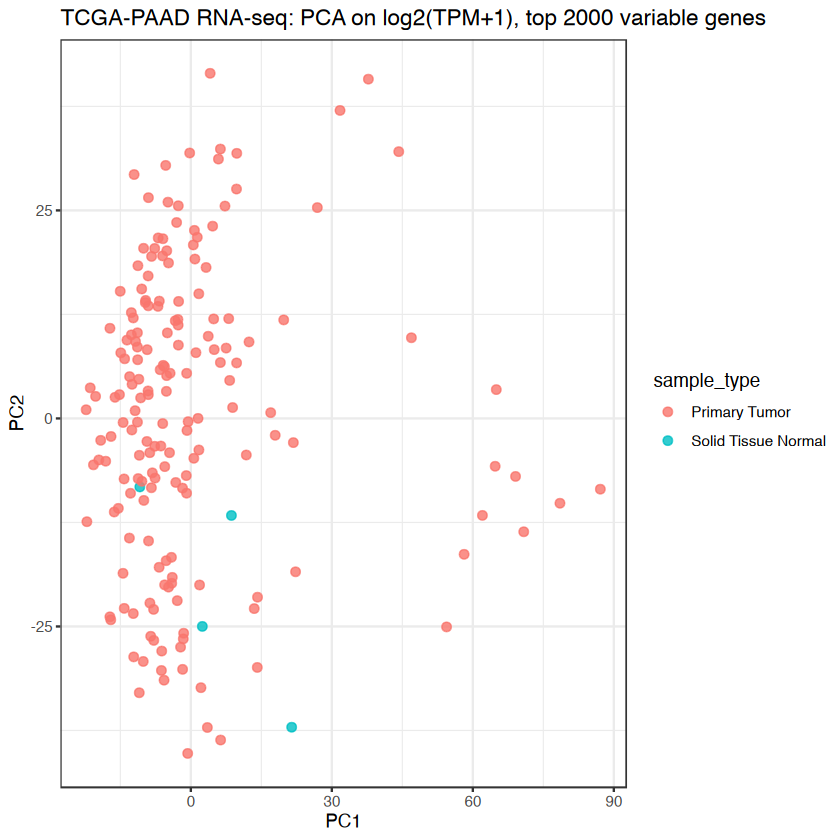

In [7]:
vars <- apply(logtpm, 1, var)
top_genes <- names(sort(vars, decreasing = TRUE))[1:min(2000, length(vars))]
pca <- prcomp(t(logtpm[top_genes, ]), scale. = TRUE)
pc_df <- as.data.frame(pca$x[, 1:2]) %>%
  rownames_to_column("barcode") %>%
  left_join(meta %>% select(barcode, sample_type), by = "barcode")

pc_outliers <- pc_df %>%
  filter(abs(PC1 - mean(PC1)) > 3 * sd(PC1) | abs(PC2 - mean(PC2)) > 3 * sd(PC2)) %>%
  pull(barcode)
add("PCA (top 2000 variable genes): samples beyond 3 SD on PC1/PC2: %d", length(pc_outliers))

ggplot(pc_df, aes(PC1, PC2, color = sample_type)) +
  geom_point(size = 2, alpha = 0.8) +
  theme_bw() +
  labs(title = "TCGA-PAAD RNA-seq: PCA on log2(TPM+1), top 2000 variable genes")
ggsave(file.path(qc_dir, "pca_sample_type.png"), width = 6, height = 5, dpi = 150)

### 6. Sample-sample correlation heatmap
Uses pheatmap's own `filename` argument (rather than manual `png()`/`dev.off()`) so the file is written reliably regardless of which graphics backend the current session (e.g. a Jupyter kernel) is using for on-screen display.

In [8]:
pheatmap(sample_cor, show_rownames = FALSE, show_colnames = FALSE,
         main = "Sample-sample Spearman correlation (log2 TPM+1)",
         filename = file.path(qc_dir, "sample_correlation_heatmap.png"),
         width = 10, height = 10)

### 7. Sex-check: XIST vs RPS4Y1 expression against clinical sex

In [9]:
clinical_path <- "clinical.project-tcga-paad.2026-10-20/clinical.tsv"
sex_check <- NA_integer_
if (file.exists(clinical_path) && all(c("XIST", "RPS4Y1") %in% rownames(tpm))) {
  clinical <- read_tsv(clinical_path, show_col_types = FALSE) %>%
    select(submitter_id = `cases.submitter_id`, sex = `demographic.sex_at_birth`) %>%
    distinct()
  sex_expr <- tibble(
    barcode = colnames(tpm),
    XIST  = tpm["XIST", ],
    RPS4Y1 = tpm["RPS4Y1", ]
  ) %>%
    left_join(meta %>% select(barcode, patient), by = "barcode") %>%
    mutate(inferred_sex = ifelse(XIST > RPS4Y1, "female", "male")) %>%
    left_join(clinical, by = c("patient" = "submitter_id")) %>%
    mutate(sex_mismatch = !is.na(sex) & tolower(sex) != inferred_sex)

  mismatches <- sex_expr %>% filter(sex_mismatch)
  sex_check <- nrow(mismatches)
  write_tsv(sex_expr, file.path(qc_dir, "sex_check.tsv"))
}
add("Clinical-vs-expression sex mismatches: %s", ifelse(is.na(sex_check), "skipped (XIST/RPS4Y1 or clinical file missing)", sex_check))

### 8. Batch-effect check: site/plate vs. tumor/normal (basis for the quantile-normalization decision)
Quantile normalization (QN) was discussed as an optional preprocessing step but not applied to this matrix. Before documenting that decision, this check asks the question QN would actually be relevant to: is there a technical (collection site / plate) signal competing with the biological signal on the top principal components? TCGA barcodes encode the tissue source site (TSS, field 2) and plate (field 6), e.g. `TCGA-IB-7888-01A-11R-2156-07` -> TSS `IB`, plate `2156`. We compare how much variance on PC1-PC5 (from the step-5 PCA) is explained (R^2 of a one-way ANOVA) by TSS/plate versus by `sample_type` (tumor vs. normal, the biological grouping).

In [10]:
bc <- meta$barcode
parts <- strsplit(bc, "-")
tss   <- sapply(parts, function(x) x[2])
plate <- sapply(parts, function(x) x[6])

tss_tab <- table(tss)
tss_grp <- ifelse(tss %in% names(tss_tab[tss_tab >= 3]), tss, "other")  # collapse rare sites

pc_df2 <- as.data.frame(pca$x[, 1:5])
pc_df2$sample_type <- meta$sample_type
pc_df2$tss   <- tss_grp
pc_df2$plate <- plate

r2 <- function(pc, grp) summary(lm(pc ~ factor(grp)))$r.squared

batch_report <- character()
badd <- function(...) batch_report <<- c(batch_report, sprintf(...))
badd("Unique TSS (collection sites): %d | unique plates: %d | unique sequencing centers: %d",
     length(unique(tss)), length(unique(plate)), length(unique(sapply(parts, function(x) x[7]))))
badd("")
badd("%-4s %10s %14s %10s %10s", "PC", "pct_var", "R2_sample_type", "R2_tss", "R2_plate")
for (i in 1:5) {
  pve <- 100 * pca$sdev[i]^2 / sum(pca$sdev^2)
  badd("PC%-2d %9.1f%% %14.3f %10.3f %10.3f",
       i, pve, r2(pc_df2[[i]], pc_df2$sample_type), r2(pc_df2[[i]], pc_df2$tss), r2(pc_df2[[i]], pc_df2$plate))
}
writeLines(batch_report, file.path(qc_dir, "batch_effect_check.txt"))
cat(paste(batch_report, collapse = "\n"), "\n")

Unique TSS (collection sites): 27 | unique plates: 12 | unique sequencing centers: 1

PC      pct_var R2_sample_type     R2_tss   R2_plate
PC1       18.6%          0.002      0.233      0.101
PC2       16.0%          0.030      0.179      0.158
PC3        7.1%          0.004      0.076      0.042
PC4        5.5%          0.020      0.092      0.097
PC5        4.7%          0.020      0.120      0.023 


### Write the QC report and the flagged-sample list

In [11]:
writeLines(report, file.path(qc_dir, "qc_report.txt"))

flagged <- unique(c(bad_sum, low_detect, pc_outliers, as.vector(near_dup_pairs)))
write_tsv(tibble(barcode = flagged), file.path(qc_dir, "flagged_samples.tsv"))

cat(paste(report, collapse = "\n"), "\n")
cat(sprintf("\nFull report: %s\nFlagged samples (%d): %s\n",
            file.path(qc_dir, "qc_report.txt"), length(flagged),
            file.path(qc_dir, "flagged_samples.tsv")))

TPM column sums: median = 999785 (expect ~1,000,000).
Samples with column sum off by >1e4 from 1e6: 0
Sample type counts: Primary Tumor=178, Solid Tissue Normal=4
Patients with >1 sample/aliquot in the matrix: 4
Sample pairs with Spearman r > 0.99 on log2(TPM+1): 0
Mean gene detection rate (TPM>0): 54.5% | samples flagged as outliers (<mean-3sd): 1
PCA (top 2000 variable genes): samples beyond 3 SD on PC1/PC2: 8
Clinical-vs-expression sex mismatches: 4 



Full report: data/qc/qc_report.txt
Flagged samples (9): data/qc/flagged_samples.tsv


## Preprocessing workflow: published XDec papers vs. this matrix

Side-by-side comparison of the preprocessing steps described in the XDec-SM (Murillo et al. 2023, BRCA) and XDec-CHI (Lewis/LaPlante et al. 2022, PDAC - methodologically closest to this project) Methods sections, versus what was actually done to build `TCGA-PAAD_TPM_raw.tsv`. For each step: what the papers did, what this matrix does, and - if different - why, what bias correction (if any) is gained or given up, and what to check if the decision is being held open rather than closed.

| Step | XDec-SM (BRCA) | XDec-CHI (PDAC) | This matrix | Status |
|---|---|---|---|---|
| Data source / pipeline | TCGA BRCA `IlluminaHiSeq_RNASeqV2`, UCSC Xena, legacy Firehose Level-3 | TCGA PAAD "level 3", UCSC Xena (same legacy pipeline); ICGC PACA-CA: STAR v2.5 + RSEM v1.3; ICGC PACA-AU: `normalized_read_count` | GDC API, **STAR - Counts** harmonized pipeline, hg38 | **Different, by necessity** |
| Expression unit | RSEM `normalized_count` | RSEM raw counts (PACA-CA) / RSEM-based normalized count (TCGA, PACA-AU) | GDC **TPM** (`tpm_unstrand`) | **Different unit, same normalization role** |
| Quantile normalization | Applied (TCGA BRCA, explicit) | Not mentioned (TCGA PAAD) | **Not applied** | **Not done** |
| Low-coverage gene filtering | Genes with avg. transformed expression < 0.01 removed | Not restated; Stage 0 restricts to ~283 informative genes anyway | **Not applied** (all 59,427 genes kept) | **Holding** |
| 0-1 saturating transform (`y = 1 - e^{-ax}`, `a = 1/max{x}`) | Applied, by the algorithm, to all reference and complex-sample profiles | Same | **Not applied** by us | **Correctly not our step** |
| Gene ID harmonization (Ensembl -> symbol) | Implicit (matched on symbol for PAM50/marker genes) | Implicit (matched on symbol for marker genes, Table S3) | Explicit: collapsed to symbol, highest-mean-TPM row kept per duplicate | **Done** |
| Sample-type filtering | "-11"-suffixed samples = healthy controls, otherwise unfiltered | Not restated | Primary Tumor + Solid Tissue Normal only (178 + 4) | **Done, matches** |
| Batch-effect correction (site/plate) | Not addressed in Methods | Not addressed in Methods | **Not applied** | **Holding** |

### Not done, and why

**Quantile normalization.** TPM already corrects for sequencing depth and gene length - the same role QN plays, just via a different (more targeted) mechanism. Applying QN on top would (a) not address the site/plate batch signal found in QC, since QN matches each sample's overall value *distribution*, not gene-specific batch shifts, and (b) risk flattening real TME-composition-driven differences in expression distribution shape between tumors - exactly the signal a deconvolution analysis is trying to measure. The PDAC-specific paper (XDec-CHI) also doesn't use it, which is some evidence it isn't a hard requirement for this application.

**Low-coverage gene filtering.** Held rather than skipped outright. XDec's Stage 0 selects its own small informative-gene subset (tens to a few hundred genes) from whichever reference is used; pre-filtering the full matrix risks dropping a gene Stage 0 would have wanted, for no benefit (genes outside the informative set are never touched by the algorithm regardless of their coverage). **What to check:** once an informative gene list is fixed - either re-derived via EDec one-vs-rest on scRNA-seq, or reused from the XDec-CHI PDAC 283-gene list (Table S3) - check coverage only within that short list, not globally.

**The 0-1 saturating transform.** This is correctly absent from our preprocessing: it's Stage 0/1 of the XDec algorithm itself (applied at runtime by the XDec/EDec R package), not something the input matrix should arrive pre-transformed with. We hand XDec linear-scale, non-negative TPM; it does this transform internally, per gene, using `max{x}` over whatever sample set is passed in.

### Holding: batch-effect correction (site/plate)

Not addressed in either paper's Methods, and not applied here, but QC (step 8 above) confirmed a real TCGA collection-site/plate signal on the top PCs (`data/qc/batch_effect_check.txt`) - larger than the tumor-vs-normal biological signal. This is being held, not skipped, because batch correction always risks removing real biology correlated with site, and shouldn't be applied without evidence it's actually corrupting something downstream cares about.

**What to check before deciding:** run XDec Stage 1 on this matrix, then test whether the estimated cell-type proportions correlate with TSS/plate. If they do, correct with `ComBat-seq` on `TCGA-PAAD_counts_raw.tsv` (TSS as the batch variable) and recompute TPM from the corrected counts - not `limma::removeBatchEffect` on log-TPM, which can produce negative values that break XDec's `1 - e^{-ax}` transform (it requires non-negative input).


## Outlier interpretation: are the flagged samples safe to keep?

Two of the QC flags above - the 8 PCA outliers and the 4 clinical-vs-expression sex mismatches - need a judgment call: keep or remove before deconvolution. This section pulls the actual evidence behind each flag (not just the count) so that call is grounded, then states the decision and what would change it.

In [12]:
## PCA-outlier detail: site (TSS), grade, purity annotations, detection rate
tss_all <- sapply(strsplit(meta$barcode, "-"), function(x) x[2])
meta_tss <- meta %>% mutate(tss = tss_all)

pc_outlier_detail <- pc_df %>%
  filter(barcode %in% pc_outliers) %>%
  left_join(meta_tss, by = "barcode") %>%
  mutate(
    detect_rate = round(detect_rate[barcode], 3),
    PC1_sd_away = round((PC1 - mean(pc_df$PC1)) / sd(pc_df$PC1), 1),
    PC2_sd_away = round((PC2 - mean(pc_df$PC2)) / sd(pc_df$PC2), 1)
  ) %>%
  select(barcode, tss, tumor_grade, PC1_sd_away, PC2_sd_away, detect_rate)

cat("PCA-outlier samples:\n")
print(as.data.frame(pc_outlier_detail), row.names = FALSE)

site_tab <- table(pc_outlier_detail$tss)
dominant_site <- names(which.max(site_tab))
cat(sprintf("\n%d of %d PCA outliers come from TSS '%s' (site has %d samples total in the cohort).\n",
            max(site_tab), nrow(pc_outlier_detail), dominant_site, sum(meta_tss$tss == dominant_site)))

grade_tab_site <- table(meta_tss$tss == dominant_site, meta_tss$tumor_grade, useNA = "ifany")
cat(sprintf("Grade distribution, TSS '%s' vs rest of cohort:\n", dominant_site))
print(grade_tab_site)

overall_detect <- mean(detect_rate); overall_detect_sd <- sd(detect_rate)
cat(sprintf("\nCohort-wide detection rate: mean = %.3f, sd = %.3f. PCA-outlier samples range %.3f-%.3f -> not a detection-rate problem.\n",
            overall_detect, overall_detect_sd, min(pc_outlier_detail$detect_rate), max(pc_outlier_detail$detect_rate)))

write_tsv(pc_outlier_detail, file.path(qc_dir, "pca_outlier_detail.tsv"))

PCA-outlier samples:


                      barcode tss tumor_grade PC1_sd_away PC2_sd_away
 TCGA-3A-A9IO-01A-11R-A38C-07  3A          G1         3.7        -0.8
 TCGA-3A-A9IV-01A-11R-A41B-07  3A          G1         3.2        -0.7
 TCGA-3A-A9IR-01A-11R-A38C-07  3A          G1         3.6        -0.4
 TCGA-3A-A9IL-01A-11R-A38C-07  3A        <NA>         3.0        -0.9
 TCGA-F2-6880-01A-11R-2156-07  F2          G1         3.4         0.2
 TCGA-3A-A9IJ-01A-11R-A39D-07  3A        <NA>         4.1        -0.6
 TCGA-3A-A9IS-01A-21R-A39D-07  3A          G1         4.5        -0.5
 TCGA-2L-AAQM-01A-11R-A39D-07  2L          G1         3.4        -0.3
 detect_rate
       0.527
       0.505
       0.545
       0.561
       0.472
       0.499
       0.498
       0.532



6 of 8 PCA outliers come from TSS '3A' (site has 17 samples total in the cohort).


Grade distribution, TSS '3A' vs rest of cohort:


       
        G1 G2 G3 G4 GX <NA>
  FALSE 17 71 34  1  2   40
  TRUE   4  7  1  0  0    5



Cohort-wide detection rate: mean = 0.545, sd = 0.034. PCA-outlier samples range 0.472-0.561 -> not a detection-rate problem.


In [13]:
## Sex-mismatch detail: compare flagged samples to confidently-sexed reference ranges
## IMPORTANT: the reference must be built from CONCORDANT calls only (inferred_sex == clinical
## sex) - filtering only on "the other gene is low" is circular, since a mismatch sample can
## satisfy that filter too (e.g. a sample with weak signal on both genes) and would then help
## set the very range it is being compared against.
concordant <- sex_expr %>% filter(!is.na(sex), tolower(sex) == inferred_sex)
confident_male   <- concordant %>% filter(tolower(sex) == "male")   %>% summarise(rps4y1_lo = min(RPS4Y1), rps4y1_hi = max(RPS4Y1))
confident_female <- concordant %>% filter(tolower(sex) == "female") %>% summarise(xist_lo = min(XIST), xist_hi = max(XIST))

cat("Reference range, CONCORDANT samples only (mismatches excluded from the reference itself):\n")
cat(sprintf("  Males   (n=%d):    RPS4Y1 range %.2f - %.2f\n",
            sum(concordant$sex == "male", na.rm = TRUE), confident_male$rps4y1_lo, confident_male$rps4y1_hi))
cat(sprintf("  Females (n=%d):  XIST range     %.2f - %.2f\n\n",
            sum(concordant$sex == "female", na.rm = TRUE), confident_female$xist_lo, confident_female$xist_hi))

mismatch_detail <- sex_expr %>% filter(!is.na(sex), tolower(sex) != inferred_sex) %>%
  select(barcode, XIST, RPS4Y1, inferred_sex, clinical_sex = sex)
cat("Flagged (mismatched) samples:\n")
print(as.data.frame(mismatch_detail), row.names = FALSE)

Reference range, CONCORDANT samples only (mismatches excluded from the reference itself):


  Males   (n=100):    RPS4Y1 range 9.37 - 482.50


  Females (n=78):  XIST range     0.39 - 64.39



Flagged (mismatched) samples:


                      barcode   XIST  RPS4Y1 inferred_sex clinical_sex
 TCGA-FB-AAQ2-01A-31R-A41B-07 3.1266  6.2992         male       female
 TCGA-RL-AAAS-01A-32R-A39D-07 0.3981  0.4498         male       female
 TCGA-XD-AAUI-01A-42R-A41B-07 4.1856 65.9238         male       female
 TCGA-IB-A5SS-01A-11R-A32O-07 1.9303  2.1368         male       female


In [14]:
## Per-sample check: does each mismatch sit near the detection floor on both
## genes, or does one gene show a real, non-marginal signal? Range-membership
## alone can mislabel a value that is only barely above the floor (e.g. 0.40
## against a 0.39 floor is technically "in range" but practically near-zero),
## so this reports the raw numbers plus range membership rather than a single
## collapsed yes/no call - see the markdown interpretation below for the read.
## Also rules out general library depth/degradation as the cause (detect_rate
## from step 4 above).
mismatch_refined <- mismatch_detail %>%
  mutate(
    detect_rate = round(detect_rate[barcode], 3),
    XIST_in_female_range = XIST   >= confident_female$xist_lo & XIST   <= confident_female$xist_hi,
    RPS4Y1_in_male_range = RPS4Y1 >= confident_male$rps4y1_lo & RPS4Y1 <= confident_male$rps4y1_hi
  )
cat("Cohort-wide detection rate: mean =", round(mean(detect_rate), 3), " sd =", round(sd(detect_rate), 3),
    "-> all 4 mismatches fall within this range, so general library depth/degradation is not the explanation.\n\n")
print(as.data.frame(mismatch_refined %>%
        select(barcode, XIST, RPS4Y1, detect_rate, XIST_in_female_range, RPS4Y1_in_male_range)), row.names = FALSE)

Cohort-wide detection rate: mean = 0.545  sd = 0.034 -> all 4 mismatches fall within this range, so general library depth/degradation is not the explanation.



                      barcode   XIST  RPS4Y1 detect_rate XIST_in_female_range
 TCGA-FB-AAQ2-01A-31R-A41B-07 3.1266  6.2992       0.531                 TRUE
 TCGA-RL-AAAS-01A-32R-A39D-07 0.3981  0.4498       0.522                 TRUE
 TCGA-XD-AAUI-01A-42R-A41B-07 4.1856 65.9238       0.562                 TRUE
 TCGA-IB-A5SS-01A-11R-A32O-07 1.9303  2.1368       0.519                 TRUE
 RPS4Y1_in_male_range
                FALSE
                FALSE
                 TRUE
                FALSE



### Next step to check: run XDec and look at the estimated proportions

The disambiguating test is downstream, not in QC: run XDec Stage 1/2 on this matrix, then check whether the **8 PCA-outlier samples'** estimated cell-type proportions are explainable by `tumor_grade` (supports real biology - keep them) or instead track **TSS membership with no biological story** (supports a technical artifact - consider excluding those samples or batch-correcting, same decision point as the step-8 batch-effect check). The same post-hoc check doubles as the resolution for the open batch-effect question from step 8 - one XDec run settles both.